In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.simulation import simulate_gbm
from src.black_scholes import bs_price, bs_delta
from src.hedging import compute_pnl, bs_delta_strategy

In [2]:
S0, K, sigma, T, n_steps = 100, 100, 0.2, 30/365, 30
dt = T / n_steps

S = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=42)
S_t = torch.tensor(S, dtype=torch.float32)

p0 = bs_price(S0, K, T, sigma)

In [3]:
tau = T - np.arange(n_steps) * dt

x1 = torch.log(S_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2 = torch.tensor(tau / T, dtype=torch.float32).expand(S_t.shape[0], n_steps)
features = torch.stack([x1, x2], dim=-1)

print(features.shape, features[0, 0])

torch.Size([100000, 30, 2]) tensor([0., 1.])


In [4]:
net_cvar = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
w = torch.tensor(0.0, requires_grad=True)
alpha = 0.95

optimizer = torch.optim.Adam(list(net_cvar.parameters()) + [w], lr=1e-3)

In [5]:

for i in range(3000):
    idx = torch.randint(0, S_t.shape[0], (10_000,))
    S_b = S_t[idx]
    deltas = net_cvar(features[idx]).squeeze(-1)
    pnl = p0 - torch.clamp(S_b[:, -1] - K, min=0) + (deltas * (S_b[:, 1:] - S_b[:, :-1])).sum(dim=1)

    loss = w + torch.clamp(-pnl - w, min=0).mean() / (1 - alpha)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if i % 300 == 0:
        print(i, loss.item(), w.item())

0 31.905078887939453 0.0010000000474974513
300 1.2679672241210938 0.2625104486942291
600 0.8898196816444397 0.4016980230808258
900 0.7679684162139893 0.4832557439804077
1200 0.7408875226974487 0.5308417081832886
1500 0.7414385676383972 0.5570823550224304
1800 0.7349758148193359 0.5709564685821533
2100 0.7397909164428711 0.5772318243980408
2400 0.7560465931892395 0.5786409974098206
2700 0.7593488693237305 0.5791579484939575


In [6]:
torch.save(net_cvar.state_dict(), "../models/net_cvar_c0.pt")

In [ ]:
def cvar(pnl, alpha=0.95):
    losses = -pnl
    var = np.quantile(losses, alpha)
    return losses[losses >=var].mean()    

In [8]:
cvar(np.array([0.3, 0.2, 0.1, 0, 0, -0.1, -0.2, -0.3, -0.8, -1.5]), alpha=0.8)

np.float64(1.15)

In [10]:
S_test = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=1)
S_test_t = torch.tensor(S_test, dtype=torch.float32)

x1_test = torch.log(S_test_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2_test = torch.tensor(tau / T, dtype=torch.float32).expand(S_test_t.shape[0], n_steps)
features_test = torch.stack([x1_test, x2_test], dim=-1)

In [11]:
net_mse = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
net_mse.load_state_dict(torch.load("../models/net_c0.pt"))

<All keys matched successfully>

In [12]:
with torch.no_grad():
    d_mse  = net_mse(features_test).squeeze(-1).numpy()
    d_cvar = net_cvar(features_test).squeeze(-1).numpy()
d_bs = bs_delta_strategy(S_test, K, T, sigma)

for name, d in [("BS delta", d_bs), ("Net MSE", d_mse), ("Net CVaR", d_cvar)]:
    pnl = compute_pnl(S_test, d, p0, K)
    print(f"{name:10s} mean={pnl.mean():.3f}  std={pnl.std():.3f}  CVaR95={cvar(pnl):.3f}")

BS delta   mean=0.000  std=0.358  CVaR95=0.833
Net MSE    mean=0.001  std=0.369  CVaR95=0.844
Net CVaR   mean=0.001  std=0.409  CVaR95=0.739


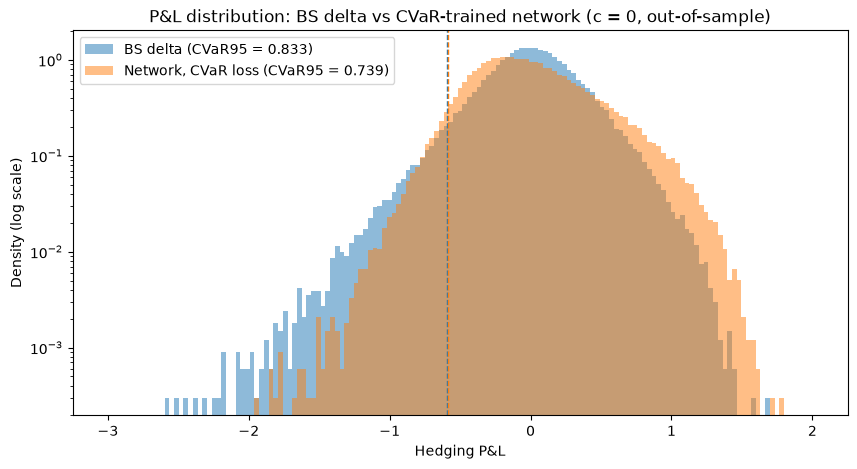

In [13]:
pnl_bs   = compute_pnl(S_test, d_bs, p0, K)
pnl_cvar = compute_pnl(S_test, d_cvar, p0, K)

bins = np.linspace(-3, 2, 150)

plt.figure(figsize=(10, 5))
plt.hist(pnl_bs,   bins=bins, density=True, alpha=0.5, label=f"BS delta (CVaR95 = {cvar(pnl_bs):.3f})")
plt.hist(pnl_cvar, bins=bins, density=True, alpha=0.5, label=f"Network, CVaR loss (CVaR95 = {cvar(pnl_cvar):.3f})")

# граница худших 5% для каждой стратегии: −VaR95
plt.axvline(-np.quantile(-pnl_bs, 0.95),   color="C0", ls="--", lw=1)
plt.axvline(-np.quantile(-pnl_cvar, 0.95), color="C1", ls="--", lw=1)

plt.yscale("log")
plt.xlabel("Hedging P&L")
plt.ylabel("Density (log scale)")
plt.title("P&L distribution: BS delta vs CVaR-trained network (c = 0, out-of-sample)")
plt.legend()
plt.savefig("../figures/pnl_bs_vs_cvar_net.png", dpi=150, bbox_inches="tight")
plt.show()